# Drug–drug interaction prediction using published similarity features

**Implementation of a method from Cheng and Zhao (2014), with a Random Forest comparison.**

This project implements similarity-based drug–drug interaction (DDI) classification using the authors' published supplementary data. Logistic regression is the selected method from the paper; a prior-only baseline and Random Forest provide comparisons. The notebook includes data checks, five-fold evaluation, a drug-disjoint experiment, feature ablation, and reproducible exports.

**Scope:** a modern implementation of the classification stage using the paper's four precomputed features. It does not reconstruct the underlying biological databases, reproduce all five original classifiers, recover the original fold assignments, or repeat the global SVM prediction network or antipsychotic case study.

**Run in Google Colab:** upload this `.ipynb`, select a standard **CPU** runtime, then **Runtime → Run all**. The dataset is embedded, so no Drive mount, API key, supplementary download, GPU, or separate file upload is needed. Saved outputs show the completed local Python run; rerunning in Colab generates a new execution record and result files.

**Research use:** scores rank the supplied dataset's labels. They are not validated clinical interaction probabilities or medication advice.

Paper: Cheng F, Zhao Z. *Machine learning-based prediction of drug–drug interactions by integrating drug phenotypic, therapeutic, chemical, and genomic properties.* JAMIA. 2014;21(e2):e278–e286. [doi:10.1136/amiajnl-2013-002512](https://doi.org/10.1136/amiajnl-2013-002512).

## 1. Research question and connection to the paper

Can four drug-pair similarities distinguish published DDI labels from sampled non-DDI labels? This relates to therapeutic discovery by evaluating computational prioritization of potentially interacting drug combinations.

The paper combines chemical, target-related, therapeutic, and adverse-reaction information. It evaluates naive Bayes, a decision tree, nearest neighbors, logistic regression, and an SVM. Here, logistic regression provides a transparent implementation of one existing AI method, while Random Forest tests a nonlinear alternative on the same inputs and splits.

| Component | This implementation |
|---|---|
| Data | All rows of the authors' `5-fold CV` worksheet |
| Inputs | Four published numerical similarities, reused without recomputation |
| Selected original model | Regularized logistic regression in scikit-learn |
| Additional comparisons | Prior-only dummy classifier and Random Forest |
| Main evaluation | New stratified five-fold pair cross-validation, seed 42 |
| Extensions | Drug-disjoint holdout, logistic feature ablation, data audit |
| Interpretation | Prediction of historical dataset labels, not clinical risk |

The original fold IDs and full software configuration are not provided in this worksheet. Therefore, these results should not be presented as an exact numerical reproduction of the paper or as an improvement over its published scores.

### Summary and contributions of the selected paper

Cheng and Zhao call their framework **heterogeneous network-assisted inference (HNAI)**. Its contribution is combining four complementary drug similarities in a compact classifier. The reported five-fold ROC-AUC spans **0.565–0.666**, with SVM performing best. The study also explores an antipsychotic case study [1].

### Limitations acknowledged in the paper

The authors identify uncertain negative labels, imperfect similarity measures, incomplete biological annotations, limitations of two-dimensional structures, and loss of detailed target-action information [1]. These limitations also constrain an implementation using their published features.

### What is implemented here

- **Reused:** all published numerical rows and all four similarity inputs.
- **Implemented:** the logistic-regression classification stage, with explicitly documented modern settings.
- **Adapted:** new stratified folds and training-only standardization; original fold assignments are unavailable.
- **Additional project work:** prior baseline, Random Forest comparison, data audit, both-drugs-unseen holdout, and a logistic-regression ablation. The paper also examines feature removal; ablation itself is not a new method.
- **Outside scope:** raw feature reconstruction, the other original classifiers (including the best-performing SVM), the global prediction network, and the antipsychotic case study.

This fulfills an **implementation of a selected component** of the paper. It is not a complete reproduction of HNAI or a clinical interaction checker.

## 2. Setup

The standard Colab scientific Python packages are sufficient. No packages are installed or upgraded automatically. Version information is recorded because library changes can alter numerical results. The accompanying `requirements-tested.txt` records the versions used for the submitted local run.

Run cells in order. A normal run creates `ddi_results/` and `ddi_results.zip` in the runtime working directory. Rerunning replaces files of the same names there. The final completion message confirms that execution reached the export step; inspect the evaluation tables to assess model performance. The standalone source also supports `python ddi_project.py --output-dir my_results`.

In [1]:
import base64
import gzip
import hashlib
import io
import json
import platform
import shutil
import sys
import textwrap
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Notebooks show figures inline. Command-line runs only save them: an
# interactive window backend can block or fail when no display is attached.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
    INTERACTIVE = True
except NameError:
    plt.switch_backend("Agg")
    INTERACTIVE = False

def show_figure(fig):
    """Show a saved figure inline in notebooks; release it in command-line runs."""
    if INTERACTIVE:
        plt.show()
    else:
        plt.close(fig)

SEED = 42
N_SPLITS = 5
THRESHOLD = 0.5  # Fixed before evaluation; never tuned on held-out predictions.
RESULTS = Path("ddi_results")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
VERSIONS = {
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
RUN_ENVIRONMENT = "Google Colab" if "google.colab" in sys.modules else "local Python/Jupyter"
RUN_STARTED = datetime.now(timezone.utc).isoformat()
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
display(pd.Series(VERSIONS, name="Version").to_frame())
print("Execution environment:", RUN_ENVIRONMENT)
print("Seed:", SEED, "| Output directory:", RESULTS)

,Version
python,3.14.6
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
matplotlib,3.11.0


Execution environment: local Python/Jupyter
Seed: 42 | Output directory: ddi_results


## 3. Published data and provenance

The embedded CSV is a value-preserving extraction of the **`5-fold CV`** sheet in `amiajnl-2013-002512-s2.xlsx`, Supplementary Table S1. It is compressed only to keep this notebook portable. Decompression checks a SHA-256 digest before any model is fitted.

- [Original article and supplementary files](https://pmc.ncbi.nlm.nih.gov/articles/PMC4173180/)
- [Original workbook download](https://pmc.ncbi.nlm.nih.gov/articles/instance/4173180/bin/amiajnl-2013-002512-s2.xlsx)
- Workbook SHA-256: `9d60b830a0c2035e3e7dfd73106a5e7db214284e2e439a37e3869264ccf83cdf`
- Extracted CSV SHA-256: `b50d5679de3f8dfd213777e0f555867573e6810b322c9024bc5c5ad071412a58`
- Retrieved: **20 September 2026**; these remain historical data from the 2014 publication.

**Source discrepancy:** the worksheet contains **6,946 DDI + 7,006 non-DDI = 13,952 rows**, covering **730 distinct drug IDs**. The positive subset covers 721 drugs. The manuscript describes 6,946 positive pairs and an equal number of negatives from 721 drugs. This notebook preserves the distributed worksheet as provided; it does not silently delete 60 negatives or exclude the additional IDs. The origin of the discrepancy is unresolved.

`non-DDI` is the authors' sampled negative label, meaning not recorded as a positive in their source network. It does **not** establish that the pair is clinically safe or a verified non-interaction.

In [2]:
# @title Restore published data and verify integrity
# Embedded numeric data from Cheng and Zhao (2014), Supplementary Table S1.
# This string contains data only; it is never executed as Python code.
CSV_SHA256 = "b50d5679de3f8dfd213777e0f555867573e6810b322c9024bc5c5ad071412a58"
WORKBOOK_SHA256 = "9d60b830a0c2035e3e7dfd73106a5e7db214284e2e439a37e3869264ccf83cdf"
SOURCE_URL = "https://pmc.ncbi.nlm.nih.gov/articles/instance/4173180/bin/amiajnl-2013-002512-s2.xlsx"
_CSV_GZIP_BASE64 = "..."
csv_bytes = gzip.decompress(base64.b64decode(_CSV_GZIP_BASE64))
assert hashlib.sha256(csv_bytes).hexdigest() == CSV_SHA256, "Embedded data digest mismatch"
raw = pd.read_csv(io.BytesIO(csv_bytes), float_precision="round_trip")
(RESULTS / "source_cv.csv").write_bytes(csv_bytes)
print(f"Verified {len(raw):,} published rows; CSV SHA-256 matches.")
display(raw.head())

Verified 13,952 published rows; CSV SHA-256 matches.


,Drug_A (Drugbank ID),Drug_B (Drugbank ID),Structural Similarity,Genomic Similarity,Therapeutic Similarity,Phenotypic Similarity,Class
0,DB00363,DB00472,0.306452,0.037037,0.666667,0.283368,DDI
1,DB00363,DB00503,0.305882,0.000000,0.666667,0.236264,DDI
2,DB00363,DB01595,0.400000,0.000000,0.666667,0.131289,DDI
3,DB00363,DB00675,0.307692,0.000000,0.000000,0.198998,DDI
4,DB00363,DB00231,0.516667,0.000000,0.666667,0.208063,DDI


## 4. Data validation and feature definitions

Only the following four numeric columns enter the models. Drug IDs are used for pair checks and splitting, never as predictive inputs. Values are taken directly from the supplement, so this project does not independently validate or recreate the original feature construction.

| Input | Information represented in the paper |
|---|---|
| Structural similarity | Chemical structure similarity |
| Genomic similarity | Similarity of drug target profiles |
| Therapeutic similarity | Similarity based on ATC classifications |
| Phenotypic similarity | Similarity of adverse-reaction profiles |

The checks below reject missing values, invalid ranges, constant columns, duplicate unordered pairs, conflicting labels, self-pairs, and unexpected IDs. They preserve input row order and do not drop any records. Identical feature vectors across different drug pairs are separately counted; they are not automatically evidence of label leakage.

In [3]:
# Schema and label validation preserve every source row and its original order.
# Only FEATURES are predictors; identifiers and labels never enter X.
RENAME = {
    "Drug_A (Drugbank ID)": "drug_a", "Drug_B (Drugbank ID)": "drug_b",
    "Structural Similarity": "structural", "Genomic Similarity": "genomic",
    "Therapeutic Similarity": "therapeutic", "Phenotypic Similarity": "phenotypic",
    "Class": "source_label",
}
FEATURES = ["structural", "genomic", "therapeutic", "phenotypic"]
assert set(raw.columns) == set(RENAME), "Unexpected source schema"
df = raw.rename(columns=RENAME).copy()
assert not df.isna().any().any(), "Missing source values"
for col in ["drug_a", "drug_b"]:
    df[col] = df[col].str.strip().str.upper()
    assert df[col].str.fullmatch(r"DB\d{5}").all(), f"Invalid IDs in {col}"
assert set(df["source_label"]) == {"DDI", "non-DDI"}, "Unexpected labels"
df["label"] = df["source_label"].map({"DDI": 1, "non-DDI": 0}).astype(int)
for feature in FEATURES:
    df[feature] = pd.to_numeric(df[feature], errors="raise")
assert np.isfinite(df[FEATURES].to_numpy()).all()
assert df[FEATURES].ge(0).all().all() and df[FEATURES].le(1).all().all()
assert (df[FEATURES].nunique() > 1).all(), "Constant input feature"
assert (df["drug_a"] != df["drug_b"]).all(), "Self-pair found"

endpoints = np.sort(df[["drug_a", "drug_b"]].to_numpy(), axis=1)
df["pair_key"] = [a + "|" + b for a, b in endpoints]
assert not df["pair_key"].duplicated().any(), "Repeated unordered pair"
assert df.groupby("pair_key")["label"].nunique().max() == 1
df.insert(0, "row_id", np.arange(len(df)))
drug_ids = np.unique(df[["drug_a", "drug_b"]].to_numpy().ravel())
positive_ids = np.unique(df.loc[df.label.eq(1), ["drug_a", "drug_b"]].to_numpy())
negative_only_ids = sorted(set(drug_ids) - set(positive_ids))
conflicting_vectors = int((df.groupby(FEATURES)["label"].nunique() > 1).sum())
AUDIT = {
    "rows": len(df), "DDI": int(df.label.sum()), "non_DDI": int(df.label.eq(0).sum()),
    "unique_drugs": len(drug_ids), "drugs_in_positive_pairs": len(positive_ids),
    "duplicate_unordered_pairs": int(df.pair_key.duplicated().sum()),
    "self_pairs": int(df.drug_a.eq(df.drug_b).sum()), "missing_values": int(df.isna().sum().sum()),
    "unique_feature_vectors": len(df[FEATURES].drop_duplicates()),
    "feature_vectors_with_both_labels": conflicting_vectors,
    "negative_only_drug_ids": negative_only_ids,
}
assert (len(df), int(df.label.sum()), len(drug_ids)) == (13952, 6946, 730)
display(pd.Series({k: v for k, v in AUDIT.items() if k != "negative_only_drug_ids"}, name="Observed").to_frame())
print("IDs appearing only in negative pairs:", ", ".join(negative_only_ids))
feature_summary = df[FEATURES].describe().T
feature_summary["distinct_values"] = df[FEATURES].nunique()
feature_summary["zero_fraction"] = df[FEATURES].eq(0).mean()
display(feature_summary.round(4))
df.to_csv(RESULTS / "validated_pairs.csv", index=False)
feature_summary.to_csv(RESULTS / "feature_summary.csv")
print("All structural data checks passed; medical label validity is not established by these checks.")

,Observed
rows,13952
DDI,6946
non_DDI,7006
unique_drugs,730
drugs_in_positive_pairs,721
duplicate_unordered_pairs,0
self_pairs,0
missing_values,0
unique_feature_vectors,13915
feature_vectors_with_both_labels,1


IDs appearing only in negative pairs: DB00309, DB00470, DB00811, DB00838, DB00917, DB00929, DB01013, DB01131, DB06706


,count,mean,std,min,25%,50%,75%,max,distinct_values,zero_fraction
structural,13952.0,0.3504,0.1390,0.0,0.2564,0.3448,0.4386,1.0000,1887,0.0111
genomic,13952.0,0.0237,0.1063,0.0,0.0000,0.0000,0.0000,1.0000,115,0.9154
therapeutic,13952.0,0.2260,0.2400,0.0,0.0000,0.1667,0.3333,1.0000,130,0.3790
phenotypic,13952.0,0.1240,0.0793,0.0,0.0566,0.1237,0.1797,0.4699,12250,0.0129


All structural data checks passed; medical label validity is not established by these checks.


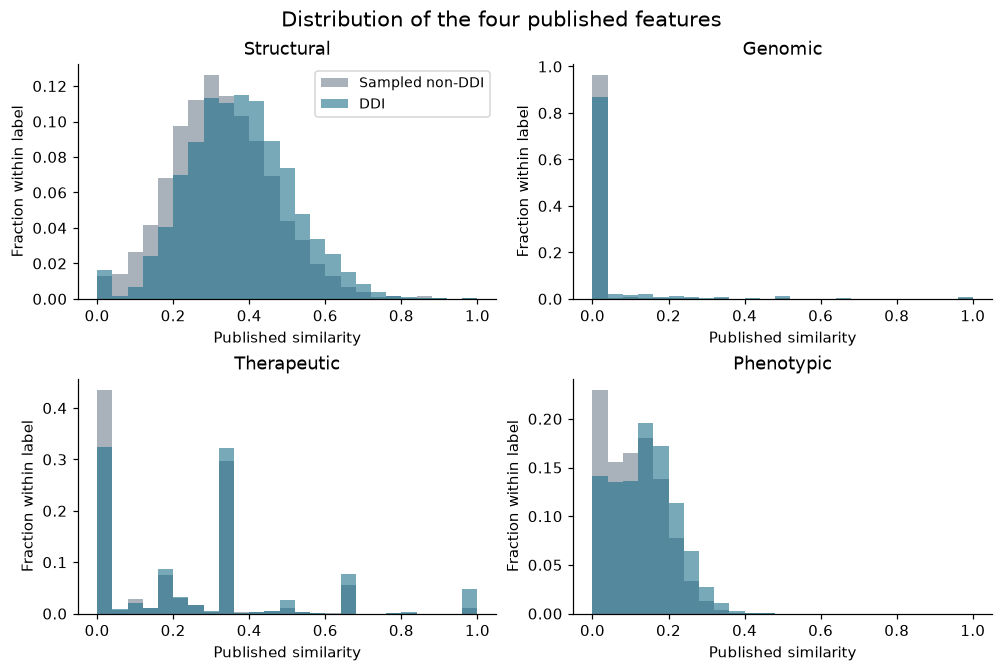

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), constrained_layout=True)
for ax, feature in zip(axes.ravel(), FEATURES):
    for label, title, color in [(0, "Sampled non-DDI", "#6C7A89"), (1, "DDI", "#176B87")]:
        values = df.loc[df.label.eq(label), feature]
        ax.hist(values, bins=np.linspace(0, 1, 26), weights=np.ones(len(values)) / len(values),
                alpha=0.58, color=color, label=title)
    ax.set(title=feature.capitalize(), xlabel="Published similarity", ylabel="Fraction within label")
axes[0, 0].legend(fontsize=9)
fig.suptitle("Distribution of the four published features", fontsize=14)
fig.savefig(FIGURES / "feature_distributions.png", bbox_inches="tight")
show_figure(fig)

## 5. Evaluation design and fixed models

**Main question:** classify an unseen pair from the published pair population. Five-fold stratified cross-validation produces one held-out score for every row. The same folds are reused for all models. Shared drug identities across folds are measured explicitly: pair cross-validation does not establish generalization to completely new drugs.

**Preprocessing:** logistic regression uses `StandardScaler` inside a pipeline, fitted only on each training fold. The Random Forest and baseline need no scaling. No feature selection, hyperparameter search, or threshold optimization uses these evaluation folds. Settings below are fixed for this implementation.

| Model | Settings |
|---|---|
| Prior baseline | `DummyClassifier(strategy='prior')` |
| Logistic regression | StandardScaler; L2 regularization, C=1, lbfgs, max_iter=2000 |
| Random Forest | 200 trees; max_depth=8; min_samples_leaf=5; max_features='sqrt'; seed=42 |

ROC-AUC is the main discrimination metric. Average precision (AP) summarizes the precision–recall curve using scikit-learn's non-interpolated definition; it is not trapezoidal PR-AUC. Accuracy, balanced accuracy, precision, recall, and F1 use the fixed score threshold 0.5. Undefined precision is reported as zero. Tables distinguish **fold mean ± sample SD** from metrics computed on **pooled out-of-fold scores**. Fold SD is not a confidence interval, and folds are not independent trials.

For each pair, logistic regression computes `z = intercept + sum(weight_j * standardized_similarity_j)` and `score = 1 / (1 + exp(-z))`. Coefficients are learned from training labels. `C=1` controls regularization strength; the 2,000-iteration setting is an optimization limit. The forest averages class scores from its fitted trees. No final clinical model is deployed.

In [5]:
MODELS = {
    "Prior baseline": DummyClassifier(strategy="prior"),
    "Logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=SEED)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=5,
        max_features="sqrt", bootstrap=True, random_state=SEED, n_jobs=2,
    ),
}
X, y = df[FEATURES], df["label"]
splits = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X, y))

def evaluate_scores(labels, scores):
    """Summarize predictions against binary source labels.

    Parameters
    ----------
    labels : one-dimensional array-like
        Source labels: 1 = reported DDI; 0 = sampled, unverified negative.
    scores : one-dimensional array-like
        Positive-class scores in [0, 1], aligned with labels. Callers must
        supply predictions from models fitted without the evaluated rows.

    Returns
    -------
    dict[str, float]
        ROC-AUC, non-interpolated average precision, accuracy, balanced
        accuracy, precision, recall and F1. Classification uses the fixed
        global THRESHOLD. Undefined precision/recall/F1 is set to zero.

    Notes
    -----
    This function checks value ranges, not training provenance. Split and
    coverage assertions below establish which rows were held out.
    """
    labels = np.asarray(labels)
    scores = np.asarray(scores)
    assert labels.ndim == scores.ndim == 1 and labels.shape == scores.shape
    assert len(labels) > 0
    assert set(np.unique(labels)) == {0, 1}, "Both classes are required"
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
    predicted = (scores >= THRESHOLD).astype(int)
    return {
        "roc_auc": roc_auc_score(labels, scores),
        "average_precision": average_precision_score(labels, scores),
        "accuracy": accuracy_score(labels, predicted),
        "balanced_accuracy": balanced_accuracy_score(labels, predicted),
        "precision": precision_score(labels, predicted, zero_division=0),
        "recall": recall_score(labels, predicted, zero_division=0),
        "f1": f1_score(labels, predicted, zero_division=0),
    }

# Clone each estimator for every fold: no learned parameters carry across folds.
# Store predictions at original row indices to prevent label/prediction mismatch.
fold_rows, split_rows, coefficient_rows = [], [], []
oof_scores = {name: np.full(len(df), np.nan) for name in MODELS}
fold_id = np.full(len(df), -1, dtype=int)
coverage = np.zeros(len(df), dtype=int)
for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    assert set(train_idx).isdisjoint(test_idx)
    assert set(df.iloc[train_idx].pair_key).isdisjoint(df.iloc[test_idx].pair_key)
    train_drugs = set(df.iloc[train_idx][["drug_a", "drug_b"]].to_numpy().ravel())
    test_pairs = df.iloc[test_idx]
    known_a, known_b = test_pairs.drug_a.isin(train_drugs), test_pairs.drug_b.isin(train_drugs)
    split_rows.append({"fold": fold, "train_rows": len(train_idx), "test_rows": len(test_idx),
                       "test_positive_rows": int(y.iloc[test_idx].sum()),
                       "both_drugs_seen": int((known_a & known_b).sum()),
                       "one_drug_seen": int((known_a ^ known_b).sum()),
                       "neither_drug_seen": int((~known_a & ~known_b).sum())})
    fold_id[test_idx] = fold
    coverage[test_idx] += 1
    for name, template in MODELS.items():
        fitted = clone(template).fit(X.iloc[train_idx], y.iloc[train_idx])
        assert list(fitted.classes_) == [0, 1]
        scores = fitted.predict_proba(X.iloc[test_idx])[:, 1]
        oof_scores[name][test_idx] = scores
        fold_rows.append({"model": name, "fold": fold, **evaluate_scores(y.iloc[test_idx], scores)})
        if name == "Logistic regression":
            # A direct guard against fitting preprocessing on all rows.
            np.testing.assert_allclose(fitted.named_steps["scale"].mean_, X.iloc[train_idx].mean())
            coefficient_rows.append({"fold": fold, **dict(zip(FEATURES, fitted.named_steps["model"].coef_[0]))})
    print(f"Completed fold {fold}/{N_SPLITS}")

assert (coverage == 1).all() and (fold_id > 0).all()
assert all(np.isfinite(scores).all() for scores in oof_scores.values())
fold_metrics = pd.DataFrame(fold_rows)
split_audit = pd.DataFrame(split_rows)
metric_names = list(evaluate_scores(y, oof_scores["Logistic regression"]))
cv_summary = fold_metrics.groupby("model", sort=False)[metric_names].agg(["mean", "std"])
display(cv_summary.round(4))
display(split_audit)
seen_fraction = split_audit.both_drugs_seen.sum() / len(df)
print(f"Both drugs occur in training for {seen_fraction:.2%} of held-out pairs.")
fold_metrics.to_csv(RESULTS / "pair_cv_fold_metrics.csv", index=False)
cv_summary.to_csv(RESULTS / "pair_cv_summary.csv")
split_audit.to_csv(RESULTS / "pair_cv_split_audit.csv", index=False)
pd.DataFrame(coefficient_rows).to_csv(RESULTS / "logistic_fold_coefficients.csv", index=False)

Completed fold 1/5


Completed fold 2/5


Completed fold 3/5


Completed fold 4/5


Completed fold 5/5


roc_auc         average_precision         accuracy  \
                       mean     std              mean     std     mean   
model                                                                    
Prior baseline       0.5000  0.0000            0.4978  0.0001   0.5022   
Logistic regression  0.6544  0.0111            0.6412  0.0152   0.6125   
Random Forest        0.6765  0.0150            0.6731  0.0158   0.6222   

                            balanced_accuracy         precision          \
                        std              mean     std      mean     std   
model                                                                     
Prior baseline       0.0001            0.5000  0.0000    0.0000  0.0000   
Logistic regression  0.0112            0.6123  0.0112    0.6191  0.0111   
Random Forest        0.0119            0.6220  0.0120    0.6320  0.0098   

                     recall              f1          
                       mean     std    mean     std  
model                                                
Prior baseline       0.0000  0.0000  0.0000  0.0000  
Logistic regression  0.5757  0.0161  0.5966  0.0136  
Random Forest        0.5766  0.0276  0.6029  0.0187

,fold,train_rows,test_rows,test_positive_rows,both_drugs_seen,one_drug_seen,neither_drug_seen
0,1,11161,2791,1390,2791,0,0
1,2,11161,2791,1389,2791,0,0
2,3,11162,2790,1389,2790,0,0
3,4,11162,2790,1389,2790,0,0
4,5,11162,2790,1389,2790,0,0


Both drugs occur in training for 100.00% of held-out pairs.


## 6. Held-out performance and error analysis

These curves and confusion matrices use one out-of-fold score per row. Every displayed score comes from a model that excluded that pair during fitting. Pooling differs from averaging fold metrics. The prior baseline's fold-wise ROC-AUC is 0.5; pooled baseline curves are omitted because small fold-specific prior changes can create uninformative cross-fold rankings.

,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,Logistic regression,0.6543,0.6398,0.6125,0.6123,0.6191,0.5757,0.5966
1,Random Forest,0.6758,0.6716,0.6222,0.6220,0.6322,0.5766,0.6031


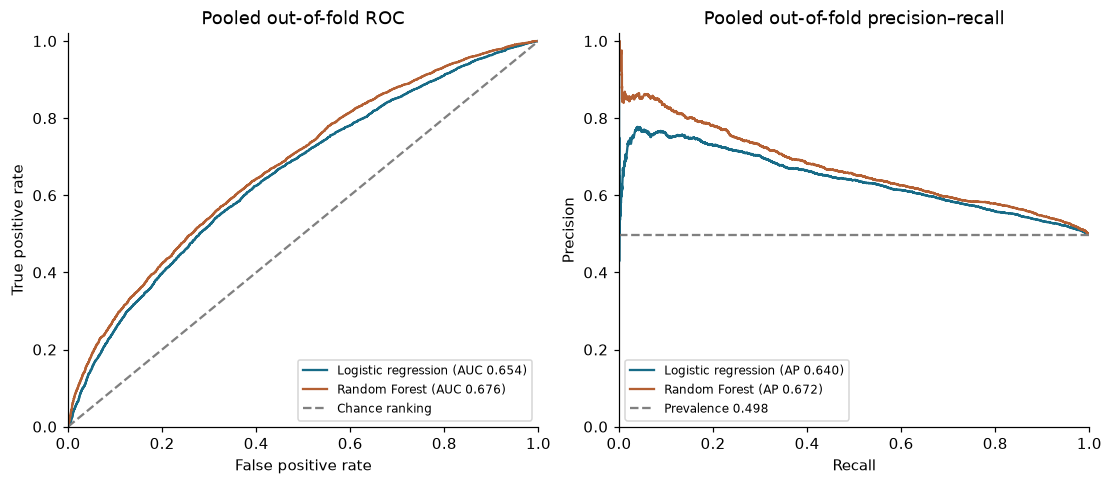

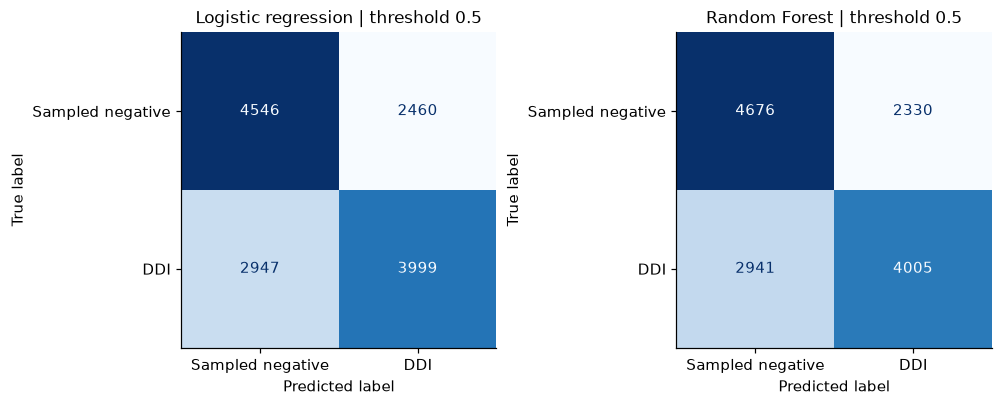

In [6]:
COMPARISONS = ["Logistic regression", "Random Forest"]
COLORS = {"Logistic regression": "#176B87", "Random Forest": "#B45F32"}
pooled_metrics = pd.DataFrame([
    {"model": name, **evaluate_scores(y, oof_scores[name])} for name in COMPARISONS
])
display(pooled_metrics.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), constrained_layout=True)
for name in COMPARISONS:
    scores = oof_scores[name]
    fpr, tpr, _ = roc_curve(y, scores)
    precision, recall, _ = precision_recall_curve(y, scores)
    axes[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(y, scores):.3f})")
    axes[1].plot(recall, precision, color=COLORS[name], label=f"{name} (AP {average_precision_score(y, scores):.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance ranking")
axes[1].axhline(y.mean(), linestyle="--", color="gray", label=f"Prevalence {y.mean():.3f}")
axes[0].set(title="Pooled out-of-fold ROC", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Pooled out-of-fold precision–recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="lower left" if ax is axes[1] else "lower right", fontsize=8)
fig.savefig(FIGURES / "pair_cv_curves.png", bbox_inches="tight")
show_figure(fig)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
for ax, name in zip(axes, COMPARISONS):
    cm = confusion_matrix(y, oof_scores[name] >= THRESHOLD, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Sampled negative", "DDI"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name + " | threshold 0.5", fontsize=11)
fig.savefig(FIGURES / "confusion_matrices.png", bbox_inches="tight")
show_figure(fig)

predictions = df[["row_id", "drug_a", "drug_b", "pair_key", "source_label", "label"]].copy()
predictions["fold"] = fold_id
for name in MODELS:
    predictions[name + "_oof_score"] = oof_scores[name]
predictions.to_csv(RESULTS / "pair_cv_predictions.csv", index=False)
pooled_metrics.to_csv(RESULTS / "pair_cv_pooled_metrics.csv", index=False)

## 7. Extension A — both drugs unseen during model training

This exploratory experiment reserves 20% of sorted drug identities using a local generator with seed 42. Training uses pairs with **both** endpoints outside that set; testing uses pairs with **both** endpoints inside it. Pairs crossing the boundary are excluded. Both endpoints are checked, so the train and test drug sets are disjoint.

The four historical features remain available for held-out drugs: this tests unseen identities at classifier training time, not drugs lacking biological annotations. The training set is smaller and the test pair population changes. A single split cannot estimate stable new-drug performance or isolate the causal effect of identity overlap. Model settings and the threshold remain fixed; no choice is made using holdout performance.

Paired percentile bootstrap intervals (2,000 resamples of the test pairs, seed 42) describe sampling uncertainty within this single test set. They do not capture variation from reserving a different set of drugs.

In [7]:
# A drug is reserved as a whole, so BOTH endpoints of a test pair are unseen.
# Crossing pairs belong to neither split; retaining them would leak identities.
rng = np.random.default_rng(SEED)
heldout_drugs = set(rng.choice(drug_ids, size=int(np.ceil(0.20 * len(drug_ids))), replace=False))
a_heldout, b_heldout = df.drug_a.isin(heldout_drugs), df.drug_b.isin(heldout_drugs)
drug_train_idx = np.flatnonzero((~a_heldout & ~b_heldout).to_numpy())
drug_test_idx = np.flatnonzero((a_heldout & b_heldout).to_numpy())
excluded_idx = np.flatnonzero((a_heldout ^ b_heldout).to_numpy())
train_ids = set(df.iloc[drug_train_idx][["drug_a", "drug_b"]].to_numpy().ravel())
test_ids = set(df.iloc[drug_test_idx][["drug_a", "drug_b"]].to_numpy().ravel())
assert train_ids.isdisjoint(test_ids), "Drug identity overlap"
assert len(drug_train_idx) + len(drug_test_idx) + len(excluded_idx) == len(df)
assert set(y.iloc[drug_train_idx]) == set(y.iloc[drug_test_idx]) == {0, 1}
holdout_counts = pd.DataFrame([
    {"partition": name, "rows": len(indices), "DDI": int(y.iloc[indices].sum()),
     "non_DDI": int(y.iloc[indices].eq(0).sum())}
    for name, indices in [("Training", drug_train_idx), ("Testing", drug_test_idx), ("Excluded crossing pairs", excluded_idx)]
])
display(holdout_counts)
print(f"Reserved {len(heldout_drugs)} drug IDs; observed in test pairs: {len(test_ids)}; shared with training: 0.")
holdout_rows = []
holdout_predictions = df.iloc[drug_test_idx][["row_id", "drug_a", "drug_b", "label"]].copy()
for name, template in MODELS.items():
    fitted = clone(template).fit(X.iloc[drug_train_idx], y.iloc[drug_train_idx])
    scores = fitted.predict_proba(X.iloc[drug_test_idx])[:, 1]
    holdout_predictions[name + "_score"] = scores
    holdout_rows.append({"model": name, **evaluate_scores(y.iloc[drug_test_idx], scores)})
holdout_metrics = pd.DataFrame(holdout_rows)
display(holdout_metrics.round(4))

# Both models are scored on every resample, so the difference interval is paired.
# Percentile intervals cover test-pair sampling only, not the reserved drug choice.
N_BOOTSTRAP = 2000
boot_rng = np.random.default_rng(SEED)
hold_y = y.iloc[drug_test_idx].to_numpy()
hold_scores = {name: holdout_predictions[name + "_score"].to_numpy() for name in COMPARISONS}
boot_auc = {name: np.empty(N_BOOTSTRAP) for name in COMPARISONS}
for b in range(N_BOOTSTRAP):
    sample = boot_rng.integers(0, len(hold_y), len(hold_y))
    assert len(np.unique(hold_y[sample])) == 2, "Bootstrap sample lacks a class"
    for name in COMPARISONS:
        boot_auc[name][b] = roc_auc_score(hold_y[sample], hold_scores[name][sample])
DIFFERENCE = "Logistic regression minus Random Forest"
boot_auc[DIFFERENCE] = boot_auc["Logistic regression"] - boot_auc["Random Forest"]
observed_auc = {name: roc_auc_score(hold_y, hold_scores[name]) for name in COMPARISONS}
observed_auc[DIFFERENCE] = observed_auc["Logistic regression"] - observed_auc["Random Forest"]
holdout_auc_ci = pd.DataFrame([
    {"quantity": name, "roc_auc": observed_auc[name],
     "ci95_lower": np.percentile(values, 2.5), "ci95_upper": np.percentile(values, 97.5)}
    for name, values in boot_auc.items()
])
display(holdout_auc_ci.round(3))
holdout_auc_ci.to_csv(RESULTS / "drug_holdout_auc_bootstrap.csv", index=False)
(RESULTS / "heldout_drug_ids.json").write_text(json.dumps(sorted(heldout_drugs), indent=2))
holdout_metrics.to_csv(RESULTS / "drug_holdout_metrics.csv", index=False)
holdout_predictions.to_csv(RESULTS / "drug_holdout_predictions.csv", index=False)
holdout_counts.to_csv(RESULTS / "drug_holdout_counts.csv", index=False)

,partition,rows,DDI,non_DDI
0,Training,8852,4351,4501
1,Testing,584,314,270
2,Excluded crossing pairs,4516,2281,2235


Reserved 146 drug IDs; observed in test pairs: 143; shared with training: 0.


,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,Prior baseline,0.5000,0.5377,0.4623,0.5000,0.0000,0.0000,0.0000
1,Logistic regression,0.6288,0.6350,0.5873,0.5911,0.6367,0.5414,0.5852
2,Random Forest,0.6209,0.6589,0.5839,0.5884,0.6360,0.5287,0.5774


,quantity,roc_auc,ci95_lower,ci95_upper
0,Logistic regression,0.629,0.582,0.672
1,Random Forest,0.621,0.575,0.665
2,Logistic regression minus Random Forest,0.008,-0.016,0.033


## 8. Extension B — feature ablation for logistic regression

Each of the four features is removed in turn, and logistic regression is refitted on the **same five pair folds**. Changes in mean ROC-AUC describe dependence on these inputs for this model and dataset. Correlated features and sampling variation limit interpretation; this is not a biological causal analysis. No ablation is selected as a new final model based on these results.

In [8]:
# Reuse the same folds for a fair descriptive comparison of feature removal.
# Never choose a replacement final model from these exploratory results.
ablation_rows = []
for removed in [None] + FEATURES:
    selected = [f for f in FEATURES if f != removed]
    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        if removed is None:
            score = oof_scores["Logistic regression"][test_idx]
        else:
            fitted = clone(MODELS["Logistic regression"]).fit(X.iloc[train_idx][selected], y.iloc[train_idx])
            score = fitted.predict_proba(X.iloc[test_idx][selected])[:, 1]
        ablation_rows.append({"removed_feature": removed or "None (all four)", "fold": fold,
                              "roc_auc": roc_auc_score(y.iloc[test_idx], score),
                              "average_precision": average_precision_score(y.iloc[test_idx], score)})
ablation_folds = pd.DataFrame(ablation_rows)
ablation = ablation_folds.groupby("removed_feature", sort=False)[["roc_auc", "average_precision"]].agg(["mean", "std"])
ablation[("roc_auc", "change_from_all")] = ablation[("roc_auc", "mean")] - ablation.loc["None (all four)", ("roc_auc", "mean")]
display(ablation.round(4))
ablation_folds.to_csv(RESULTS / "ablation_fold_metrics.csv", index=False)
ablation.to_csv(RESULTS / "ablation_summary.csv")

roc_auc         average_precision                 roc_auc
                   mean     std              mean     std change_from_all
removed_feature                                                          
None (all four)  0.6544  0.0111            0.6412  0.0152          0.0000
structural       0.6337  0.0083            0.6312  0.0066         -0.0207
genomic          0.6470  0.0117            0.6336  0.0156         -0.0074
therapeutic      0.6393  0.0129            0.6261  0.0168         -0.0151
phenotypic       0.6342  0.0147            0.6197  0.0158         -0.0203

## 9. Inspect a genuinely held-out pair score

The lookup returns an existing pair's out-of-fold scores and its **source dataset label**. It accepts DrugBank IDs in either order, rejects identical or unknown IDs, and does not invent features for unseen pairs. The example below is simply the first source row, selected without inspecting its prediction; it is not evidence of clinical validity.

After running all cells, add a code cell and run:
```python
display(inspect_pair("DB00363", "DB00472"))
```
`source_label` is the authors' recorded label; `fold` identifies the held-out fold. `Logistic regression_oof_score` and `Random Forest_oof_score` are outputs from two different models, each trained without that row. “OOF” means **out of fold**. Larger scores favor the DDI class. At the fixed threshold, scores **at least 0.5** predict DDI and scores below 0.5 predict the sampled-negative class. A score of 0.8 is not an established 80% clinical interaction risk, and it says nothing about severity.

`inspect_pair` only retrieves evaluated pairs; entering two arbitrary drug names or a pair absent from the source will not generate a new prediction. To inspect every input row, use `display(df)`; to list the available IDs, use `display(pd.Series(drug_ids, name="DrugBank ID"))`.

In [9]:
def inspect_pair(drug_a, drug_b):
    """Return existing out-of-fold predictions for one published drug pair.

    Parameters
    ----------
    drug_a, drug_b : str
        DrugBank IDs, e.g. "DB00363" and "DB00472". Case and surrounding
        whitespace are normalized, and argument order does not matter.

    Returns
    -------
    pandas.DataFrame
        One row with the source row ID, drug IDs, source label, fold, and
        the logistic-regression and Random Forest held-out scores.

    Raises
    ------
    ValueError
        For non-string inputs, identical IDs, unknown IDs, or a pair absent
        from the source worksheet. Requires the evaluation above to finish.

    Notes
    -----
    This is a lookup, not training or a predictor for arbitrary drug pairs.
    Scores are not calibrated clinical probabilities or measures of severity.
    """
    if not isinstance(drug_a, str) or not isinstance(drug_b, str):
        raise ValueError("Enter two DrugBank IDs as strings, for example DB00363.")
    a, b = drug_a.strip().upper(), drug_b.strip().upper()
    if a == b:
        raise ValueError("Choose two distinct drugs; self-pairs are outside this dataset.")
    unknown = sorted({a, b} - set(drug_ids))
    if unknown:
        raise ValueError("ID not in this source dataset: " + ", ".join(unknown))
    key = "|".join(sorted([a, b]))
    match = predictions.loc[predictions.pair_key.eq(key)]
    if match.empty:
        raise ValueError("This pair is absent from the published CV worksheet; no held-out score is available.")
    return match.drop(columns=["pair_key", "label", "Prior baseline_oof_score"]).reset_index(drop=True)

example_a, example_b = df.loc[0, ["drug_a", "drug_b"]]
display(inspect_pair(example_a, example_b).round(4))
pd.testing.assert_frame_equal(inspect_pair(example_a, example_b), inspect_pair(example_b, example_a))
print("Scores are held-out classifier outputs, not clinical risk percentages.")

,row_id,drug_a,drug_b,source_label,fold,Logistic regression_oof_score,Random Forest_oof_score
0,0,DB00363,DB00472,DDI,1,0.7323,0.8127


Scores are held-out classifier outputs, not clinical risk percentages.


## 10. Results, contributions, and limitations

The following numerical summary is generated from this run, so it updates automatically if the environment or configuration changes.

In [10]:
lr_mean = cv_summary.loc["Logistic regression", ("roc_auc", "mean")]
lr_sd = cv_summary.loc["Logistic regression", ("roc_auc", "std")]
rf_mean = cv_summary.loc["Random Forest", ("roc_auc", "mean")]
rf_sd = cv_summary.loc["Random Forest", ("roc_auc", "std")]
lr_ap = cv_summary.loc["Logistic regression", ("average_precision", "mean")]
rf_ap = cv_summary.loc["Random Forest", ("average_precision", "mean")]
hold = holdout_metrics.set_index("model")
ci = holdout_auc_ci.set_index("quantity")
summary_text = textwrap.dedent(f'''
**Observed results.** On {len(df):,} published pairs, five-fold mean ROC-AUC was
**{lr_mean:.3f} ± {lr_sd:.3f}** for logistic regression and **{rf_mean:.3f} ± {rf_sd:.3f}**
for Random Forest (mean ± fold SD). Mean AP was **{lr_ap:.3f}** and **{rf_ap:.3f}**,
respectively. These compare with a fold-wise baseline ROC-AUC of 0.500.

Both drugs already occurred in training for **{seen_fraction:.2%}** of pair-CV test rows.
In the separate drug-disjoint experiment, the test set contained **{len(drug_test_idx):,} pairs**;
ROC-AUC was **{hold.loc['Logistic regression', 'roc_auc']:.3f}** for logistic regression and
**{hold.loc['Random Forest', 'roc_auc']:.3f}** for Random Forest. This single holdout has a different
training size and test population, so its scores are not directly interchangeable with pair-CV estimates.
The paired 95% bootstrap interval for logistic regression minus Random Forest is
**{ci.loc[DIFFERENCE, 'ci95_lower']:.3f} to {ci.loc[DIFFERENCE, 'ci95_upper']:.3f}**.

The results quantify prediction of the published labels. They do not show that a drug combination
is safe, that a newly predicted interaction is confirmed, or that this implementation outperforms
the original paper under an identical protocol.
''')
# Render Markdown in notebooks; print plain text in command-line runs.
if INTERACTIVE:
    display(Markdown(summary_text))
else:
    print(summary_text.replace("**", ""))


**Observed results.** On 13,952 published pairs, five-fold mean ROC-AUC was
**0.654 ± 0.011** for logistic regression and **0.676 ± 0.015**
for Random Forest (mean ± fold SD). Mean AP was **0.641** and **0.673**,
respectively. These compare with a fold-wise baseline ROC-AUC of 0.500.

Both drugs already occurred in training for **100.00%** of pair-CV test rows.
In the separate drug-disjoint experiment, the test set contained **584 pairs**;
ROC-AUC was **0.629** for logistic regression and
**0.621** for Random Forest. This single holdout has a different
training size and test population, so its scores are not directly interchangeable with pair-CV estimates.
The paired 95% bootstrap interval for logistic regression minus Random Forest is
**-0.016 to 0.033**.

The results quantify prediction of the published labels. They do not show that a drug combination
is safe, that a newly predicted interaction is confirmed, or that this implementation outperforms
the original paper under an identical protocol.


### Project contributions

1. An executable implementation of a published similarity-based classification approach using the authors' numerical data, with a direct connection between each feature and the source paper.
2. Explicit source provenance, data integrity checks, and disclosure of the worksheet–manuscript discrepancy.
3. A shared evaluation protocol for logistic regression, a prior baseline, and Random Forest, including precision–recall metrics and held-out error analysis.
4. A drug-disjoint evaluation and feature ablation that expose limits of a single pair-split score.

These are implementation and evaluation contributions for this project, not claims of a new DDI method.

### Limitations and future work

- **Provisional negative labels.** Sampled non-DDI pairs may include unrecorded interactions. Evaluation inherits this uncertainty; class 0 does not mean safe.
- **Historical coverage.** The supplementary data reflect the source study, not current comprehensive drug knowledge. Missing annotations and unequal study intensity can influence similarity values.
- **Partial implementation.** Precomputed features are reused. Their raw construction, other original models, the global SVM prediction network, and the antipsychotic case study are not recreated. The source count discrepancy and missing original fold IDs prevent an exact numerical reproduction claim.
- **Evaluation scope.** Most pair-CV test drugs appear in training. The additional holdout tests both endpoints but only for one reserved set of drugs with existing annotations. Fold SD is descriptive, not a confidence interval or significance test.
- **Probability interpretation.** The roughly balanced training sample does not represent clinical prevalence. No calibration or prospective evaluation is performed; scores should not be interpreted as patient-specific probabilities.
- **Biological scope.** Four symmetric similarities do not represent dose, timing, direction, interaction mechanism, severity, or individual patient factors. Classification cannot establish causal drug interactions.
- **Next research steps.** Resolve the source discrepancy, rebuild features from dated source releases, evaluate repeated drug-disjoint and temporal splits, and test on independently curated interactions before making broader claims.

## 11. Export reproducibility artifacts

This cell saves the source and validated data, fold assignments and predictions, evaluation tables, figures, and execution provenance. The ZIP contains results from the **current** run; it does not submit anything or upload data. In Colab, use the file panel to download `ddi_results.zip` and **File → Download → Download .ipynb** to save the executed notebook.

In [11]:
provenance = {
    "paper_doi": "10.1136/amiajnl-2013-002512", "source_url": SOURCE_URL,
    "source_file": "amiajnl-2013-002512-s2.xlsx", "sheet": "5-fold CV",
    "retrieved_date": "2026-09-20", "workbook_sha256": WORKBOOK_SHA256,
    "embedded_csv_sha256": CSV_SHA256, "seed": SEED, "folds": N_SPLITS,
    "threshold": THRESHOLD, "feature_columns": FEATURES, "audit": AUDIT,
    "versions": VERSIONS, "execution_environment": RUN_ENVIRONMENT,
    "execution_started_utc": RUN_STARTED,
    "execution_finished_utc": datetime.now(timezone.utc).isoformat(),
    "model_parameters": {name: {k: str(v) for k, v in model.get_params(deep=True).items()}
                         for name, model in MODELS.items()},
    "drug_holdout": {"reserved_drug_count": len(heldout_drugs), "test_drugs_observed": len(test_ids),
                     "train_rows": len(drug_train_idx), "test_rows": len(drug_test_idx),
                     "excluded_crossing_rows": len(excluded_idx), "shared_train_test_drugs": 0},
}
(RESULTS / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
(RESULTS / "README.txt").write_text(
    "DDI project results using Cheng and Zhao (2014) published features.\n"
    "pair_cv_fold_metrics.csv: one row per model and fold.\n"
    "pair_cv_summary.csv: mean and sample SD across folds (two header rows).\n"
    "pair_cv_predictions.csv: one held-out score per model per source row.\n"
    "drug_holdout_*: single exploratory split with both drug endpoints disjoint.\n"
    "ablation_*: exploratory removal of one feature at a time for logistic regression.\n"
    "provenance.json: source hashes, settings, audit, runtime and versions.\n"
    "Source label non-DDI means sampled negative, not clinically verified safe.\n",
    encoding="utf-8",
)
zip_path = shutil.make_archive(str(RESULTS), "zip", root_dir=RESULTS)
print("Completed. All data, fold coverage, preprocessing, and endpoint-disjointness checks passed.")
print("Results archive:", f"{RESULTS}.zip")
print("Retain the executed notebook and technical report together with these artifacts.")

Completed. All data, fold coverage, preprocessing, and endpoint-disjointness checks passed.
Results archive: ddi_results.zip
Retain the executed notebook and technical report together with these artifacts.


## 12. References

1. Cheng F, Zhao Z. Machine learning-based prediction of drug–drug interactions by integrating drug phenotypic, therapeutic, chemical, and genomic properties. *J Am Med Inform Assoc.* 2014;21(e2):e278–e286. [DOI](https://doi.org/10.1136/amiajnl-2013-002512); [PubMed](https://pubmed.ncbi.nlm.nih.gov/24644270/).
2. Cheng and Zhao supplementary materials. `amiajnl-2013-002512-s2.xlsx`, Table S1, worksheet `5-fold CV`. [Source](https://pmc.ncbi.nlm.nih.gov/articles/instance/4173180/bin/amiajnl-2013-002512-s2.xlsx). Accessed 20 September 2026.
3. Scikit-learn documentation. [Pipelines and leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage); [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html); [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html); [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

Attribution: the supplementary numerical values are from Cheng and Zhao's published data. Notebook organization, validation, modern classifier implementation, and additional evaluations are project work.